<center><h1>Wang_Selena_HW6</h1></center>

Name: Selena Wang
<br>
Github Username: slnwang
<br>
USC ID: 6791950498

## 1. Tree-Based Methods

Import packages

In [2]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 5.3 MB/s  0:00:005.2 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_val_score)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, roc_auc_score, 
RocCurveDisplay, classification_report)
from sklearn.base import clone

from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### (a) Download the APS Failure data

In [25]:
train_df = pd.read_csv("../data/aps_failure_training_set.csv", skiprows = 20, na_values = "na")

test_df = pd.read_csv("../data/aps_failure_test_set.csv", skiprows = 20, na_values = "na")

print(train_df.shape)
print(test_df.shape)

display(train_df.head())

(60000, 171)
(16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Types of imputation:
* univariate: imputing i-th feature dimension by only susing values that are non-missing in that feature dimension (mean, median, mode)
* multivariate: imputing using the netire set of available feature dimensions (iterative)
* nearest neighbours: imputing using KNN approach.

For this assignment, I will be using median imputation (univariate) because it is less sensitive to extremes than using the mean. This means any missing values in each feature will be replaced with that feature's training-set median. The same median will be applied to the test set. 

Source: https://scikit-learn.org/stable/modules/impute.html

In [26]:
X_train = train_df.drop(columns = "class")
X_test = test_df.drop(columns = "class")

y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

print("Train missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

imputer = SimpleImputer(strategy = "median")

X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns = X_test.columns, index = X_test.index)

print("Train missing values:", X_train_imputed.isna().sum().sum())
print("Test missing values:", X_test_imputed.isna().sum().sum())

Train missing values: 850015
Test missing values: 228680
Train missing values: 0
Test missing values: 0


#### (ii) Calculate the coefficient of variation

In [27]:
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof = 1)

cv = feature_stds / feature_means.replace(0, np.nan)

cv_df = pd.DataFrame({"Mean": feature_means, "Sample Standard Deviation": feature_stds, "CV": cv}).sort_values("CV", ascending = False)

display(cv_df.head(13))

,Mean,Sample Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


#### (iii) Plot a correlation matrix

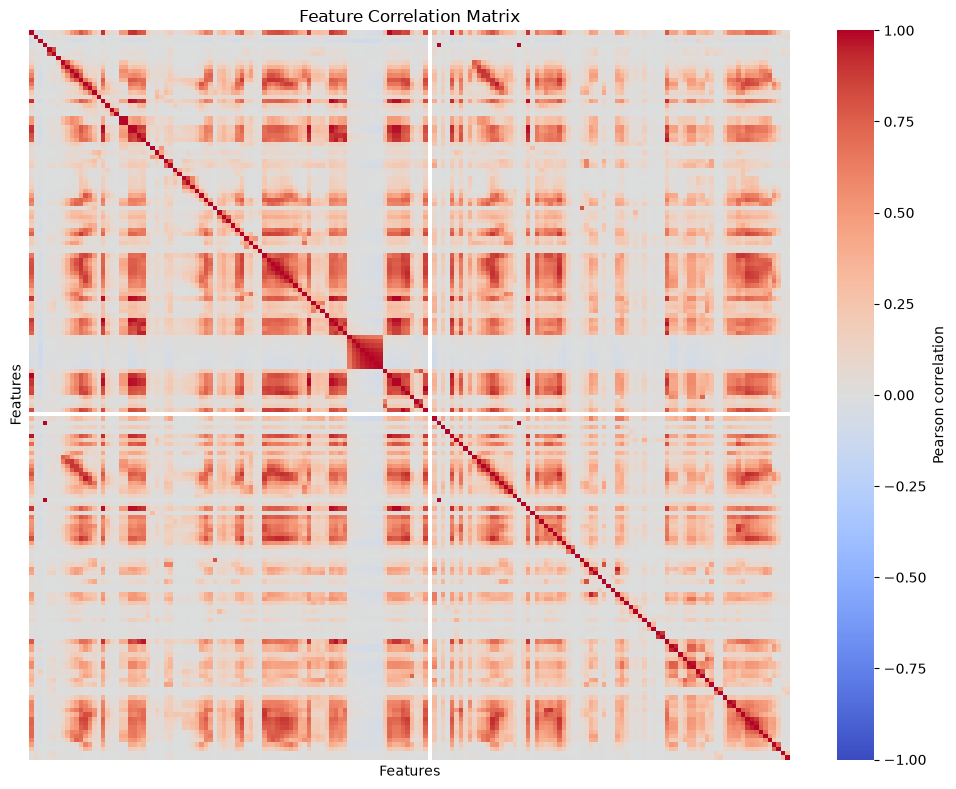

In [28]:
corr_matrix = X_train_imputed.corr()
plt.figure(figsize = (10, 8))

sns.heatmap(corr_matrix, cmap = "coolwarm", vmin = -1, vmax = 1, center = 0, 
            xticklabels = False, yticklabels = False, cbar_kws={"label": "Pearson correlation"})

plt.title("Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

In [29]:
top_feats = cv_df["CV"].dropna().nlargest(13).index

plot_df = X_train_imputed[top_features].copy()
plot_df["Class"] = y_train.map({0: "Negative", 1: "Positive"})

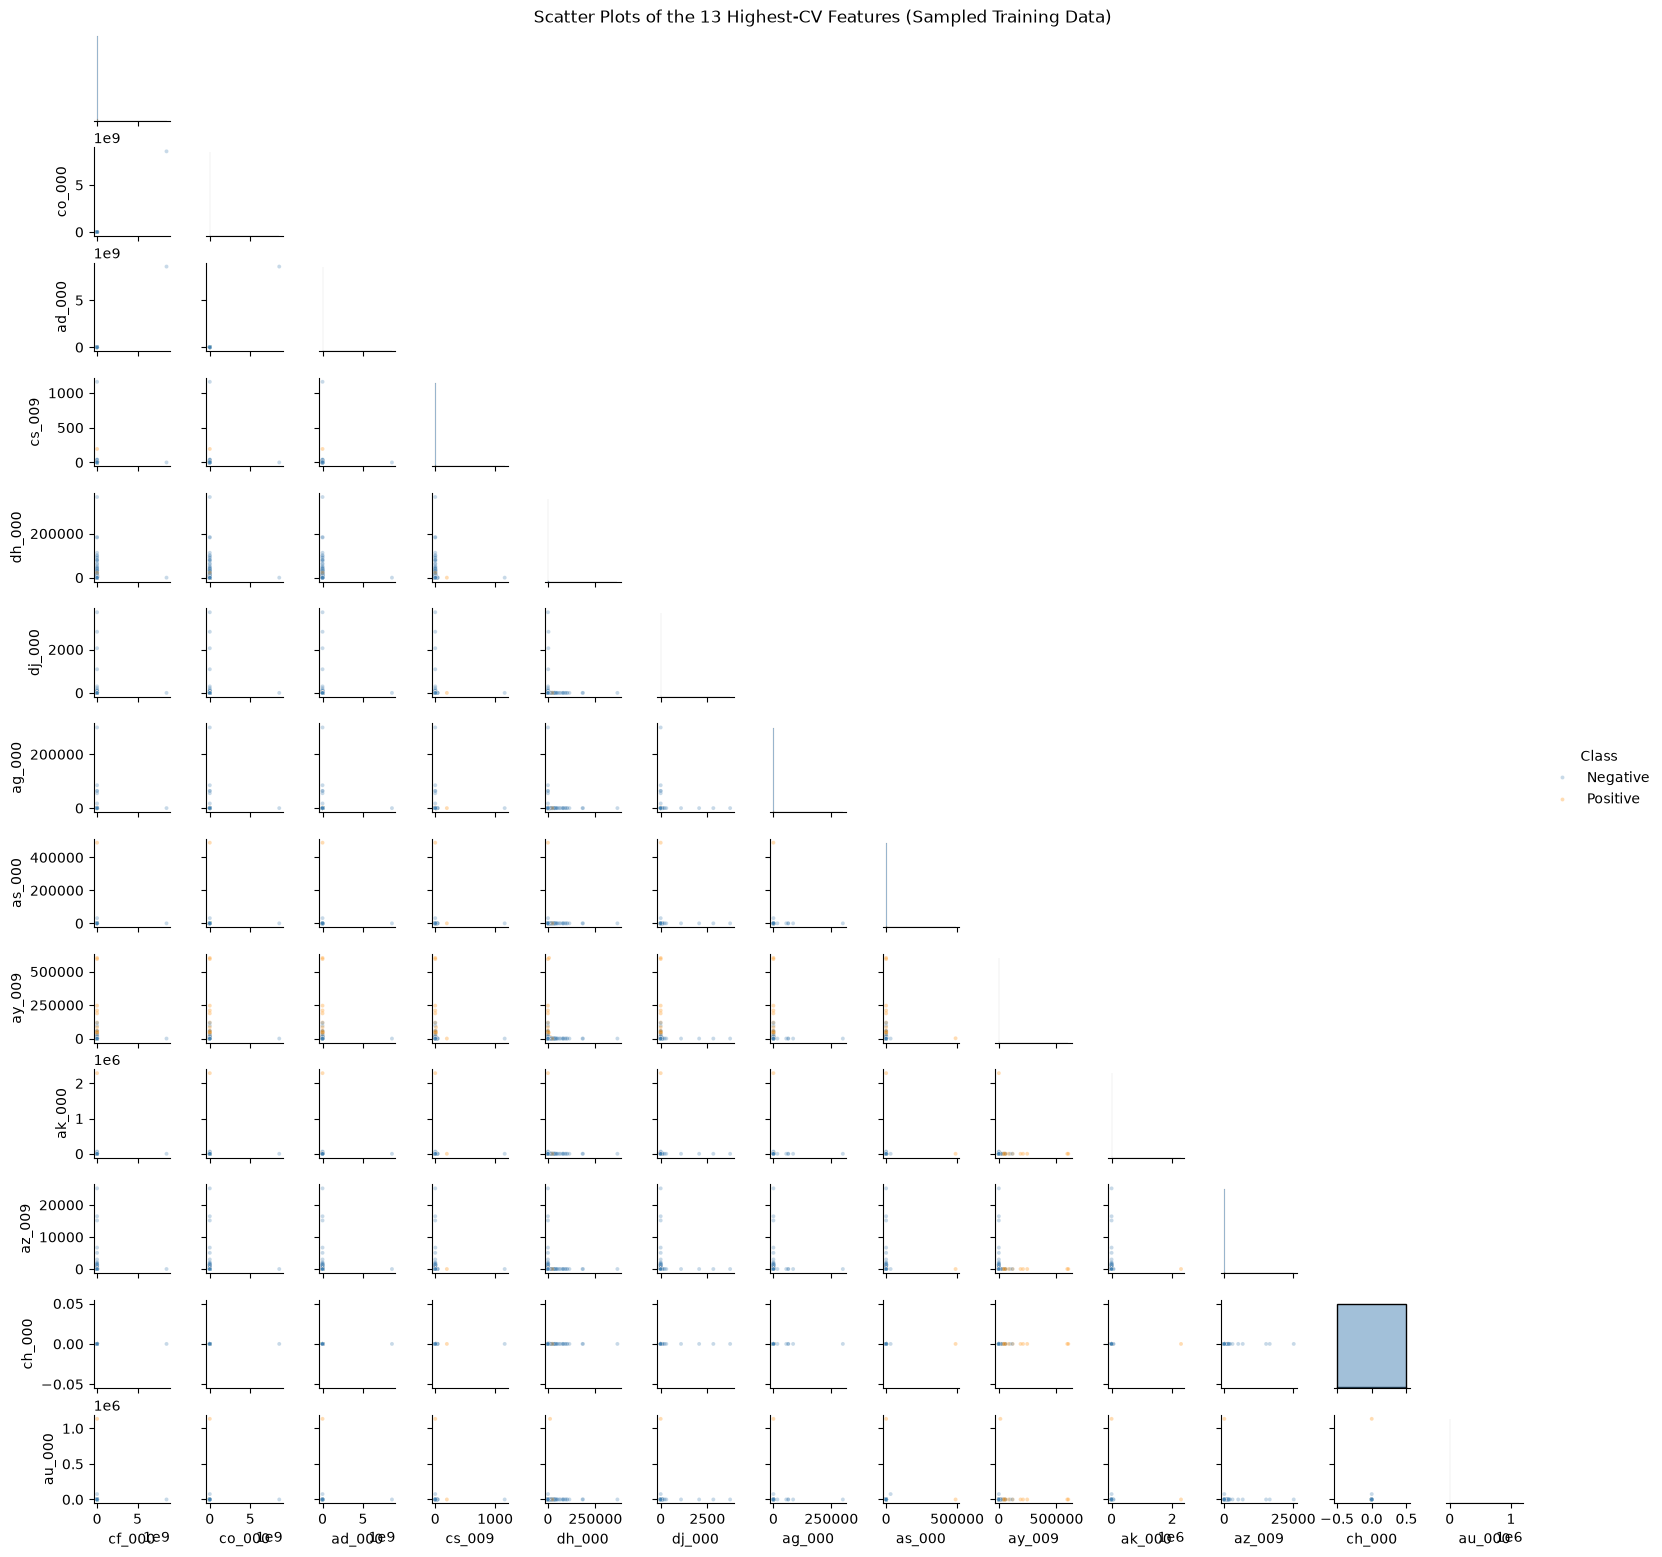

In [30]:
scatter_df = plot_df.sample(n = min(6000, len(plot_df)), random_state = 5)

g = sns.pairplot(scatter_df, vars = top_features.tolist(), hue = "Class", hue_order = ["Negative", "Positive"],
                 palette={"Negative": "steelblue", "Positive": "darkorange"}, corner = True, diag_kind = "hist", 
                 height = 1.2, plot_kws = {"alpha": 0.3, "s": 8, "rasterized": True})

g.fig.suptitle("Scatter Plots of the 13 Highest-CV Features (Sampled Training Data)", y = 1)
plt.show()

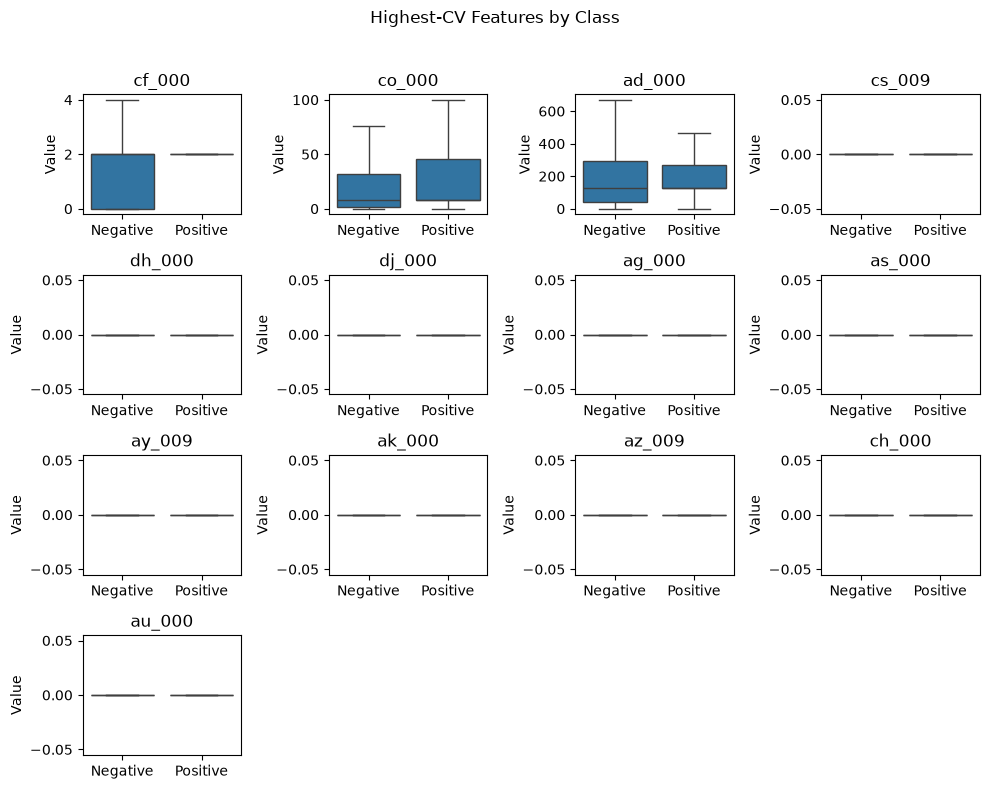

In [31]:
fig, axes = plt.subplots(4, 4, figsize=(10, 8))
axes = axes.flatten()

for ax, feature in zip(axes, top_features):
    sns.boxplot(data = plot_df, x = "Class", y = feature, order = ["Negative", "Positive"], showfliers = False, ax = ax)

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Highest-CV Features by Class", fontsize = 12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### (v) Is this data set imbalanced?

In [32]:
counts = pd.DataFrame({
    "Training": train_df["class"].value_counts(),
    "Test": test_df["class"].value_counts()}).reindex(["neg", "pos"])

display(counts)

,Training,Test
class,,
neg,59000,15625
pos,1000,375


Looking at the output, we can see that the dataset is highly imbalanced

### (c) Train a random forest

In [36]:
rf = RandomForestClassifier(n_estimators = 300, class_weight = None, bootstrap = True, 
                            oob_score = True, random_state = 5, n_jobs = -1)

rf.fit(X_train_imputed, y_train)

train_pred = rf.predict(X_train_imputed)
test_pred = rf.predict(X_test_imputed)

train_prob = rf.predict_proba(X_train_imputed)[:, 1]
test_prob = rf.predict_proba(X_test_imputed)[:, 1]
train_error = 1 - accuracy_score(y_train, train_pred)
test_error = 1 - accuracy_score(y_test, test_pred)

train_auc = roc_auc_score(y_train, train_prob)
test_auc = roc_auc_score(y_test, test_prob)

oob_error = 1 - rf.oob_score_

results = pd.DataFrame({
    "Misclassification Rate": [train_error, test_error],
    "AUC": [train_auc, test_auc]
}, index=["Training", "Test"])

display(results.round(4))

print(f"OOB error: {oob_error:.4f}")
print(f"Test error: {test_error:.4f}")
print(f"OOB - test error Comparison: {oob_error - test_error:.4f}")

,Misclassification Rate,AUC
Training,0.0000,1.0000
Test,0.0076,0.9942


OOB error: 0.0060
Test error: 0.0076
OOB - test error Comparison: -0.0016


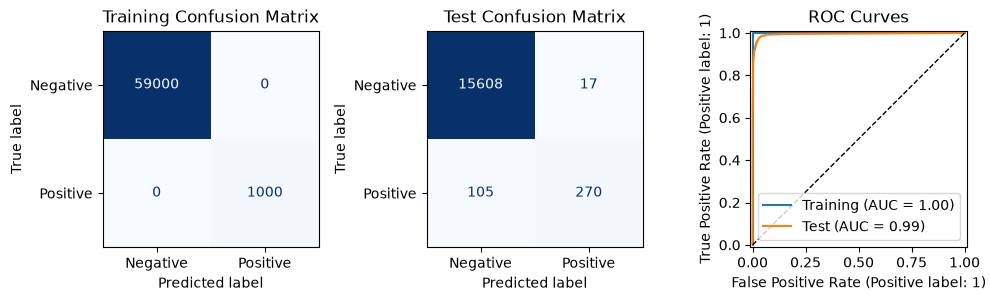

In [35]:
fig, axes = plt.subplots(1, 3, figsize = (10, 8))

ConfusionMatrixDisplay.from_predictions(y_train, train_pred, labels = [0, 1], display_labels = ["Negative", "Positive"],
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[0])
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels = [0, 1], display_labels = ["Negative", "Positive"], 
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[1])
axes[1].set_title("Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_train, train_prob, name = "Training", ax = axes[2])

RocCurveDisplay.from_predictions(y_test, test_prob, name = "Test", ax = axes[2])

axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[2].set_title("ROC Curves")

plt.tight_layout()
plt.show()

### (d) Research class imbalance in random forest

Source: https://www.geeksforgeeks.org/machine-learning/bagging-and-random-forest-for-imbalanced-classification/ 

Random Forests can favour the majority class when they are trained on data with class imbalance. We can address this by using class weighting, bootstrap-based class weighting and random undersampling. Class weighting can give the minority class a greater weight during the training. Undersampling reduces the number of obsercations in the majority class.

For this assignment, I will be using the `class_weight` parameter. Setting it to `balanced_subsample` calculates the inverse-frequency class weights separately for each of the tree's bootstrap samples.

In [41]:
rf_balanced = clone(rf).set_params(class_weight = "balanced_subsample")

rf_balanced.fit(X_train_imputed, y_train)

train_pred_bal = rf_balanced.predict(X_train_imputed)
test_pred_bal = rf_balanced.predict(X_test_imputed)

train_prob_bal = rf_balanced.predict_proba(X_train_imputed)[:, 1]
test_prob_bal = rf_balanced.predict_proba(X_test_imputed)[:, 1]

train_error_bal = 1 - accuracy_score(y_train, train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, test_pred_bal)

train_auc_bal = roc_auc_score(y_train, train_prob_bal)
test_auc_bal = roc_auc_score(y_test, test_prob_bal)

oob_error_bal = 1 - rf_balanced.oob_score_

results_bal = pd.DataFrame({
    "Misclassification Rate": [train_error_bal, test_error_bal],
    "AUC": [train_auc_bal, test_auc_bal]
}, index=["Training", "Test"])

display(results_bal.round(4))

print(f"OOB error: {oob_error_bal:.4f}")
print(f"Test error: {test_error_bal:.4f}")
print(f"OOB − test error Comparison: {oob_error_bal - test_error_bal:.4f}")

,Misclassification Rate,AUC
Training,0.0000,1.0000
Test,0.0107,0.9945


OOB error: 0.0075
Test error: 0.0107
OOB − test error Comparison: -0.0031


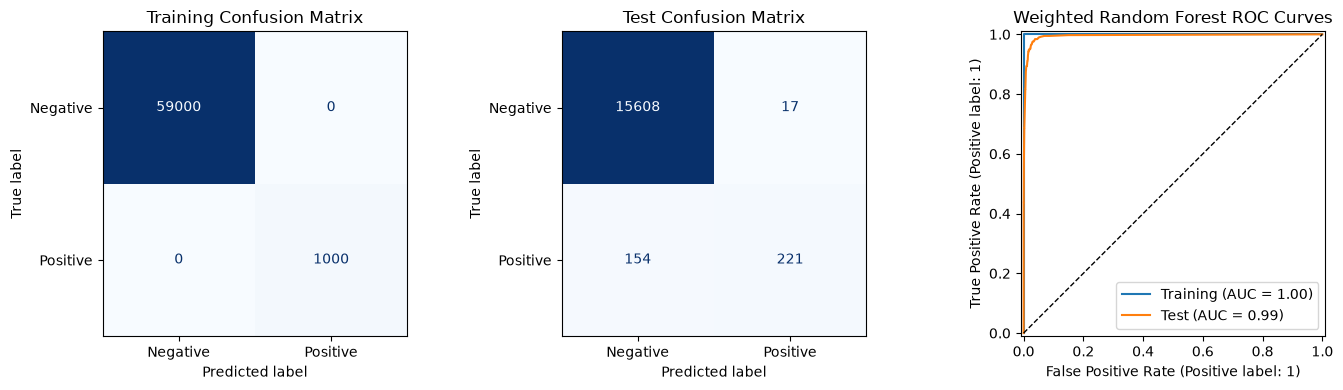

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, actual, predicted, title in [
    (axes[0], y_train, train_pred_bal, "Training Confusion Matrix"),
    (axes[1], y_test, test_pred_bal, "Test Confusion Matrix")
]:
    ConfusionMatrixDisplay.from_predictions(actual, predicted, labels = [0, 1], display_labels = ["Negative", "Positive"],
                                            cmap = "Blues", colorbar = False, values_format = "d", ax = ax)
    ax.set_title(title)

RocCurveDisplay.from_predictions(y_train, train_prob_bal, name = "Training", ax = axes[2])
RocCurveDisplay.from_predictions(y_test, test_prob_bal, name = "Test", ax = axes[2])

axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[2].set_title("Weighted Random Forest ROC Curves")

plt.tight_layout()
plt.show()

Comparing to the original Random Forest, we can see that the weighted model has a slightly better AUC but it also increased the test misclassification from 0.76% to 1.07%. The False Negatives also increased from 105 to 154 while false positives remained at 17. Even though AUC increased slightly from 0.9942 to 0.9945, the threshold still worsened. Therefore, adding these weights did not improve the performance of classification. 

### (e) XGBoost and Model Trees

In [55]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
    ("model", XGBClassifier(booster = "gblinear", objective = "binary:logistic", reg_lambda = 0, n_estimators = 500, 
                            learning_rate = 0.1, updater = "coord_descent", feature_selector = "cyclic", eval_metric = "logloss", 
                            random_state = 5, n_jobs = 1, verbosity = 0))])

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 5)
param_grid = {"model__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1, 1]}

xgb_search = GridSearchCV(estimator = xgb_pipeline, param_grid = param_grid, scoring = "accuracy", cv = cv, 
                          refit = True, n_jobs = 2, verbose = 2)

xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_
cv_error = 1 - xgb_search.best_score_

print("Selected alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"Mean CV misclassification: {cv_error:.4f}")

cv_results = pd.DataFrame({"Alpha": xgb_search.cv_results_["param_model__reg_alpha"],
                           "Mean CV Error": 1 - xgb_search.cv_results_["mean_test_score"]})

display(cv_results.round(5))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Selected alpha: 0.01
Mean CV misclassification: 0.0140


,Alpha,Mean CV Error
0,0.0000,0.01667
1,0.0001,0.01667
2,0.0010,0.01667
3,0.0100,0.01405
4,0.1000,0.01667
5,1.0000,0.01667


In [56]:
train_pred_xgb = best_xgb.predict(X_train)
test_pred_xgb = best_xgb.predict(X_test)

train_prob_xgb = best_xgb.predict_proba(X_train)[:, 1]
test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

train_error_xgb = 1 - accuracy_score(y_train, train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test, test_pred_xgb)

results_xgb = pd.DataFrame({
    "Misclassification Rate": [train_error_xgb,test_error_xgb],
    "AUC": [roc_auc_score(y_train, train_prob_xgb), roc_auc_score(y_test, test_prob_xgb)]
}, index=["Training", "Test"])

display(results_xgb.round(4))

print(f"CV error: {cv_error:.4f}")
print(f"Test error: {test_error_xgb:.4f}")
print(f"CV − test error: {cv_error - test_error_xgb:.4f}")

,Misclassification Rate,AUC
Training,0.0138,0.9804
Test,0.0176,0.9877


CV error: 0.0140
Test error: 0.0176
CV − test error: -0.0035


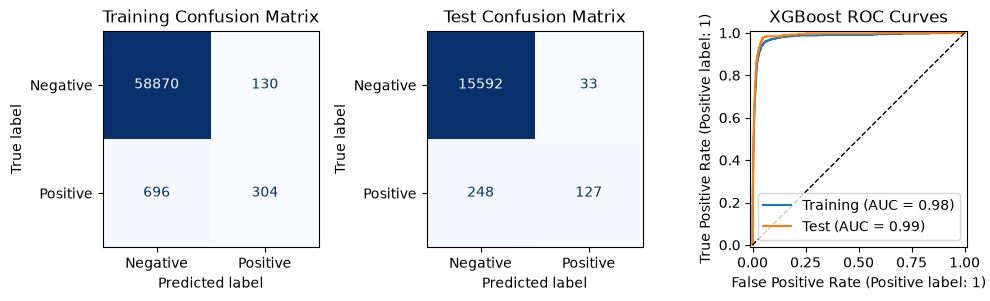

In [57]:
fig, axes = plt.subplots(1, 3, figsize = (10, 8))

ConfusionMatrixDisplay.from_predictions(y_train, train_pred_xgb, display_labels = ["Negative", "Positive"],
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[0])
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, test_pred_xgb, display_labels = ["Negative", "Positive"],
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[1])
axes[1].set_title("Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_train, train_prob_xgb, name = "Training", ax = axes[2])
RocCurveDisplay.from_predictions(y_test, test_prob_xgb, name = "Test", ax = axes[2])

axes[2].plot([0, 1], [0, 1], "k--", linewidth = 1)
axes[2].set_title("XGBoost ROC Curves")

plt.tight_layout()
plt.show()

Five-fold cross-validation selected $\alpha = 0.01$, with a mean misclassification rate of approximately 1.405%. Training and test misclassification rates were 1.38% and 1.76%, respectively. The CV estimate underestimated test error by approximately 0.35 percentage points. Training and test AUC were 0.9804 and 0.9877.

Despite the high test AUC, the model detected only 127 of 375 positive cases, giving a recall of 33.87%, and missed 248 failures. Thus, the model ranked observations well overall but detected relatively few positive cases at the default classification threshold.

### (f) Use SMOTE to pre-process your data

In [58]:
xgb_smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state = 5)),
    ("model", clone(xgb_pipeline.named_steps["model"]))
])

xgb_smote_search = GridSearchCV(estimator = xgb_smote_pipeline, param_grid = param_grid, scoring = "accuracy", cv = cv,
                                refit = True,n_jobs = 2, verbose = 2)

xgb_smote_search.fit(X_train, y_train)

best_xgb_smote = xgb_smote_search.best_estimator_
cv_error_smote = 1 - xgb_smote_search.best_score_

print("Selected alpha:", xgb_smote_search.best_params_["model__reg_alpha"])
print(f"Mean CV misclassification: {cv_error_smote:.5f}")

cv_results_smote = pd.DataFrame({
    "Alpha": xgb_smote_search.cv_results_["param_model__reg_alpha"],
    "Mean CV Error": 1 - xgb_smote_search.cv_results_["mean_test_score"]
})

display(cv_results_smote.round(5))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Selected alpha: 1
Mean CV misclassification: 0.02377


,Alpha,Mean CV Error
0,0.0000,0.02468
1,0.0001,0.02455
2,0.0010,0.02442
3,0.0100,0.02963
4,0.1000,0.03047
5,1.0000,0.02377


In [59]:
train_pred_smote = best_xgb_smote.predict(X_train)
test_pred_smote = best_xgb_smote.predict(X_test)

train_prob_smote = best_xgb_smote.predict_proba(X_train)[:, 1]
test_prob_smote = best_xgb_smote.predict_proba(X_test)[:, 1]

train_error_smote = 1 - accuracy_score(y_train, train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test, test_pred_smote)

results_smote = pd.DataFrame({
    "Misclassification Rate": [train_error_smote, test_error_smote],
    "AUC": [
        roc_auc_score(y_train, train_prob_smote),
        roc_auc_score(y_test, test_prob_smote)
    ]
}, index = ["Training", "Test"])

display(results_smote.round(4))

print(f"CV error: {cv_error_smote:.4f}")
print(f"Test error: {test_error_smote:.4f}")
print(f"CV − test error: {cv_error_smote - test_error_smote:.4f}")

,Misclassification Rate,AUC
Training,0.0254,0.9691
Test,0.0266,0.9736


CV error: 0.0238
Test error: 0.0266
CV − test error: -0.0029


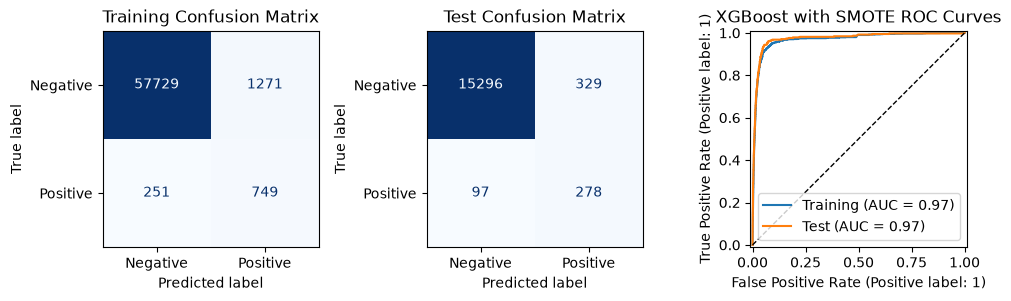

In [60]:
fig, axes = plt.subplots(1, 3, figsize = (10, 8))

ConfusionMatrixDisplay.from_predictions(y_train, train_pred_smote, display_labels = ["Negative", "Positive"],
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[0])
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, test_pred_smote, display_labels = ["Negative", "Positive"], 
                                        cmap = "Blues", colorbar = False, values_format = "d", ax = axes[1])
axes[1].set_title("Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_train, train_prob_smote, name = "Training", ax = axes[2])
RocCurveDisplay.from_predictions(y_test, test_prob_smote, name = "Test", ax = axes[2])

axes[2].plot([0, 1], [0, 1], "k--", linewidth = 1)
axes[2].set_title("XGBoost with SMOTE ROC Curves")

plt.tight_layout()
plt.show()

## 2. ISLR 6.6.3

a) Training RSS will **steadily decrease** because we allowing the constraint to relax and expand. So, the minimum training RSS is unable to increase and eventually will level off at the ordinary least squares minimum

b) The Test RSS will **decrease then increase in a U shape** because the greater flexibility will initially reduce underfitting but eventually, that same additional flexibility will cause overfitting. This change is reflected in the decrease then increase in a U shape pattern

c) Variance will **steadily increase** because generally speaking, the less regularization, the more the fitted model will be sensitive to the trianing sample. This results in a steadily increasing variance.

d) The squared bias will **steadily decrease** because by allowing the shrinkage to relax, we are generally reducing the bias caused by the restriction of coefficients.

e) The irreducible error will **remain constant** because the noise in the data-generating process does not depend on the model's flexibility and thus will not change. 

## 3. ISLR 6.6.5

a) Let $x_{11} = x_{12} = x_{1}$ and $x_{21} = x_{22} = x_{2}$

Then the optimization problem is $\min_{\beta_1,\beta_2} \left[(y_1 - \beta_1 x_{1} - \beta_2 x_{1})^2 + (y_2 - \beta_1 x_{2} - \beta_2 x_{2})^2 +\lambda(\beta_1^2 + \beta_2^2) \right]$

b)Since the predictors are identical, the ridge objective is

$L(\beta_1, \beta_2) = (y_1 - \beta_1 x_1 - \beta_2 x_1)^2 + (y_2 - \beta_1 x_2 - \beta_2 x_2)^2 + \lambda (\beta_1^2 + \beta_2^2)$

Taking partial derivatives with respect to $\beta_1$ and $\beta_2$ and setting them equal to zero gives

$\frac{\partial L}{\partial \beta_1} = -2 x_1 (y_1 - \beta_1 x_1 - \beta_2 x_1) - 2 x_2 (y_2 - \beta_1 x_2 - \beta_2 x_2) + 2 \lambda \beta_1 = 0$

$\frac{\partial L}{\partial \beta_2} = -2 x_1 (y_1 - \beta_1 x_1 - \beta_2 x_1) - 2 x_2 (y_2 - \beta_1 x_2 - \beta_2 x_2) + 2 \lambda \beta_2 = 0$

Subtracting the second equation from the first gives

$2 \lambda (\beta_1 - \beta_2) = 0$

Therefore, for $\lambda > 0$, the ridge coefficient estimates satisfy $\hat{\beta}_1 = \hat{\beta}_2$.

c) We can get the lasso optimization by replacing squared penalty with absolute values so: $\min_{\beta_1,\beta_2} \left[(y_1 - \beta_1 x_1 - \beta_2 x_1)^2 +(y_2 - \beta_1 x_2-\beta_2 x_2)^2 +\lambda(|\beta_1|+|\beta_2|)\right]$

d) Since the two predictors are identical, the predictions depend only on $\beta_1 + \beta_2$. If the coefficients have the same sign, their lasso penalty also depends only on this sum because $|\beta_1| + |\beta_2| = |\beta_1 + \beta_2|$.

Therefore, any same-sign coefficient pair with the optimal sum gives the same RSS and penalty. For example, if the optimal sum is $2$, then $(2, 0)$, $(1, 1)$, and $(0, 2)$ are equally good solutions. More generally, every pair $(a, 2 - a)$ with $0 \leq a \leq 2$ is a solution.

Thus, the coefficients are not unique when the optimal sum is nonzero. If the optimal sum is zero and $\lambda > 0$, the unique solution is $(0, 0)$.

## 4. ISLR 8.4.5

6 trees predict Red and 4 predict Green, so by majority, the vote is **Red**. 

Calculating the average probability, we get $p = 0.45$. Since $0.45 < 0.5$, the average probability is **Green**

## 5. ISLR 9.7.3

a) The plot shows the four Red and three Blue observations.

b) The optimal separating hyperplane is $0.5 - X_1 + X_2 = 0$.

c) Classify an observation as Red if $0.5 - X_1 + X_2 > 0$, and Blue otherwise. Therefore, $\beta_0 = 0.5$, $\beta_1 = -1$, and $\beta_2 = 1$.

d) The dashed margin boundaries are $X_2 = X_1$ and $X_2 = X_1 - 1$. The perpendicular margin on each side is $M = \frac{1}{2 \sqrt{2}}$.

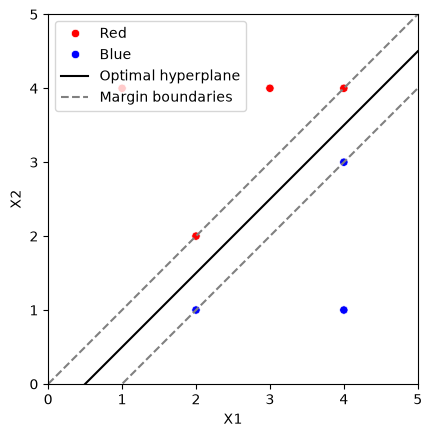

In [54]:
sns.scatterplot(data = df_obs, x = "X1", y = "X2",
                hue = "Class", palette = {"Red": "red", "Blue": "blue"})

x = np.linspace(0, 5, 100)

plt.plot(x, x - 0.5, color = "black", label = "Optimal hyperplane")
plt.plot(x, x, "--", color = "gray", label = "Margin boundaries")
plt.plot(x, x - 1, "--", color = "gray")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.gca().set_aspect("equal")
plt.legend()
plt.show()

e) The support vectors are observations 2, 3, 5, and 6: $(2, 2)$, $(4, 4)$, $(2, 1)$, and $(4, 3)$. These lie on the margin boundaries.

f) Observation 7, $(4, 1)$, is not a support vector. So, a sufficiently small movement keeps it outside the margin and the optimal hyperplane remains unchanged.

g) A nonoptimal separating hyperplane is $0.25 - X_1 + X_2 = 0$. It separates the original seven observations, but its margin is smaller than that of the optimal hyperplane because it lies closer to the Red observations.

h) Adding a Blue observation at $(2, 3)$ makes the classes no longer linearly separable. This point lies inside the triangle formed by the Red observations $(1, 4)$, $(2, 2)$, and $(4, 4)$, so no straight line can separate all Red and Blue observations.

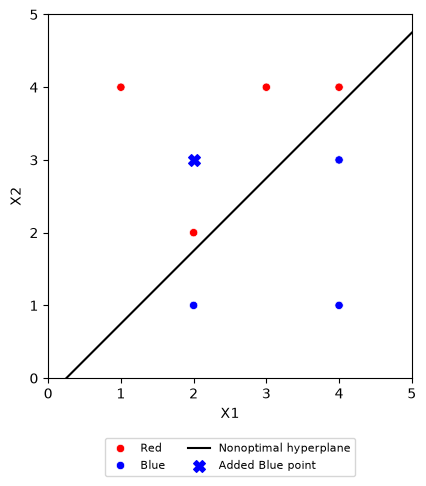

In [53]:
plt.figure(figsize = (5, 5))

sns.scatterplot(data = df_obs, x = "X1", y = "X2",
                hue = "Class", palette = {"Red": "red", "Blue": "blue"})

plt.plot(x, x - 0.25, color = "black", label = "Nonoptimal hyperplane")
plt.scatter(2, 3, color = "blue", marker = "X", s = 70, label = "Added Blue point")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.gca().set_aspect("equal")
plt.legend(loc = "upper center", bbox_to_anchor = (0.5, -0.15), ncol = 2, fontsize = 8)
plt.tight_layout()
plt.show()